In [1]:
import pandas as pd
import numpy as np

In [2]:
data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'
!wget $data

--2026-10-22 15:10:58--  https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1475504 (1.4M) [text/plain]
Saving to: ‘data.csv.12’

data.csv.12         100%[===================>]   1.41M  --.-KB/s    in 0.1s    

2026-10-22 15:10:59 (13.7 MB/s) - ‘data.csv.12’ saved [1475504/1475504]



In [3]:
df=pd.read_csv('data.csv')

In [4]:
df.head

<bound method NDFrame.head of           Make       Model  Year                Engine Fuel Type  Engine HP  \
0          BMW  1 Series M  2011     premium unleaded (required)      335.0   
1          BMW    1 Series  2011     premium unleaded (required)      300.0   
2          BMW    1 Series  2011     premium unleaded (required)      300.0   
3          BMW    1 Series  2011     premium unleaded (required)      230.0   
4          BMW    1 Series  2011     premium unleaded (required)      230.0   
...        ...         ...   ...                             ...        ...   
11909    Acura         ZDX  2012     premium unleaded (required)      300.0   
11910    Acura         ZDX  2012     premium unleaded (required)      300.0   
11911    Acura         ZDX  2012     premium unleaded (required)      300.0   
11912    Acura         ZDX  2013  premium unleaded (recommended)      300.0   
11913  Lincoln      Zephyr  2006                regular unleaded      221.0   

       Engine Cylinde

In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [6]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [7]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [8]:
df = df.astype({
    col: 'object'
    for col in df.select_dtypes(include=['string']).columns
})

In [9]:
strings = list(df.dtypes[df.dtypes == 'object'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [10]:
df.dtypes


make                  object
model                 object
year                   int64
engine_fuel_type      object
engine_hp            float64
engine_cylinders     float64
transmission_type     object
driven_wheels         object
number_of_doors      float64
market_category       object
vehicle_size          object
vehicle_style         object
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [11]:
for col in strings:
    df[col]=df[col].str.lower().str.replace(' ','_')

In [12]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [13]:
df

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


In [14]:
print(col)

vehicle_style


In [15]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

make
['bmw' 'audi' 'fiat' 'mercedes-benz' 'chrysler']
48

model
['1_series_m' '1_series' '100' '124_spider' '190-class']
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
['premium_unleaded_(required)' 'regular_unleaded'
 'premium_unleaded_(recommended)' 'flex-fuel_(unleaded/e85)' 'diesel']
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
['manual' 'automatic' 'automated_manual' 'direct_drive' 'unknown']
5

driven_wheels
['rear_wheel_drive' 'front_wheel_drive' 'all_wheel_drive'
 'four_wheel_drive']
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
['factory_tuner,luxury,high-performance' 'luxury,performance'
 'luxury,high-performance' 'luxury' 'performance']
71

vehicle_size
['compact' 'midsize' 'large']
3

vehicle_style
['coupe' 'convertible' 'sedan' 'wagon' '4dr_hatchback']
16

highway_mpg
[26 28 27 25 24]
59

city_mpg
[19 20 18 17 16]
69

popularity
[3916 3105  819  617 1013]
48

msrp
[46135 40650 36350 29450 345

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

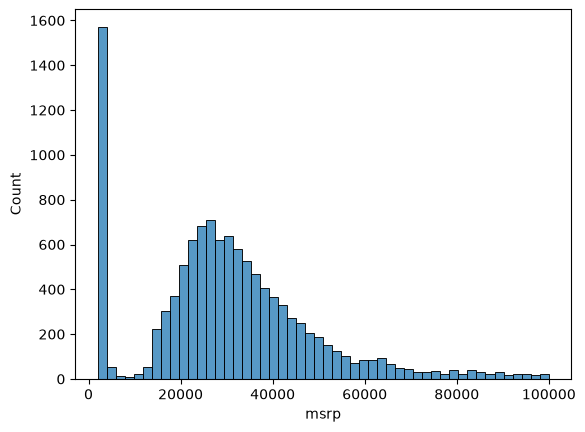

In [17]:
sns.histplot(df.msrp[df.msrp<100000],bins=50)

<Axes: xlabel='engine_hp', ylabel='Count'>

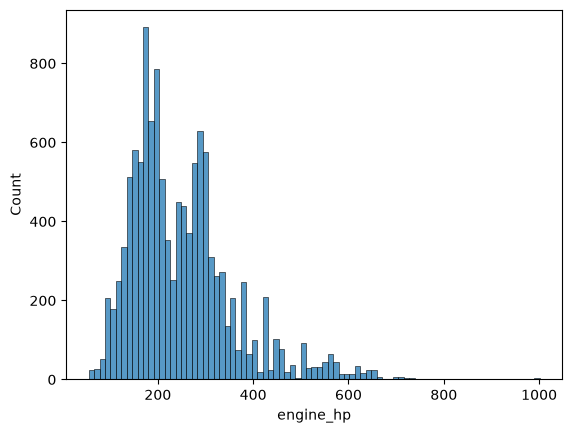

In [18]:
sns.histplot(df.engine_hp)

In [19]:
np.log([0+1,1+1,10+1,1000+1,100000+1])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [20]:
np.log1p([0,1,10,1000,100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [21]:
np.log([0,1,10,1000,100000])

/tmp/ipykernel_2707/4180585470.py:1: RuntimeWarning: divide by zero encountered in log
  np.log([0,1,10,1000,100000])


array([       -inf,  0.        ,  2.30258509,  6.90775528, 11.51292546])

In [22]:
price_logs=np.log1p(df.msrp)

<Axes: xlabel='msrp', ylabel='Count'>

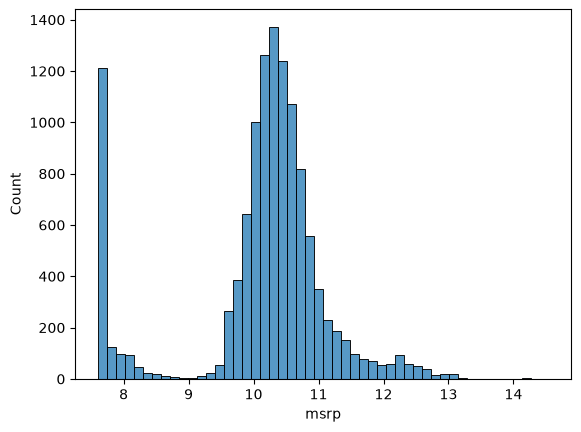

In [23]:
sns.histplot(price_logs,bins=50)

In [24]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [25]:
n=len(df)

In [26]:
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test

In [27]:
n,n_val,n_test,n_train

(11914, 2382, 2382, 7150)

In [28]:
df.iloc[:10]

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
5,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,31200
6,bmw,1_series,2012,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,26,17,3916,44100
7,bmw,1_series,2012,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,39300
8,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,36900
9,bmw,1_series,2013,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,27,18,3916,37200


In [29]:
df.iloc[12:]

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
12,bmw,1_series,2013,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,44400
13,bmw,1_series,2013,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,19,3916,37200
14,bmw,1_series,2013,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,19,3916,31500
15,bmw,1_series,2013,premium_unleaded_(required),320.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,convertible,25,18,3916,48250
16,bmw,1_series,2013,premium_unleaded_(required),320.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,43550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,46120
11910,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,56670
11911,acura,zdx,2012,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50620
11912,acura,zdx,2013,premium_unleaded_(recommended),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,hatchback,luxury",midsize,4dr_hatchback,23,16,204,50920


In [30]:
df_val=df.iloc[:n_val]
df_test=df.iloc[n_val:n_val+n_test]
df_train=df.iloc[n_val+n_test:]

In [31]:
idx=np.arange(n)
np.random.shuffle(idx)

In [32]:
df_train=df.iloc[idx[:n_train]]
df_val=df.iloc[idx[n_train:n_train+n_val]]
df_test=df.iloc[idx[n_train+n_val:]]

In [33]:
np.random.seed(2)

idx=np.arange(n)
np.random.shuffle(idx)


In [34]:
len(df_train),len(df)

(7150, 11914)

In [35]:
len(df_train),len(df_val),len(df_test)

(7150, 2382, 2382)

In [36]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [37]:
y_train=np.log1p(df_train.msrp.values)
y_val=np.log1p(df_val.msrp.values)
y_test=np.log1p(df_test.msrp.values)


In [38]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [39]:
df.iloc[10]

make                                         bmw
model                                   1_series
year                                        2013
engine_fuel_type     premium_unleaded_(required)
engine_hp                                  300.0
engine_cylinders                             6.0
transmission_type                         manual
driven_wheels                   rear_wheel_drive
number_of_doors                              2.0
market_category          luxury,high-performance
vehicle_size                             compact
vehicle_style                              coupe
highway_mpg                                   28
city_mpg                                      20
popularity                                  3916
msrp                                       39600
Name: 10, dtype: object

In [40]:
xi=[453,11,86]

w0=7.17
w=[0.01,0.04,0.002]

In [41]:
def linear_regression(xi):
    n = len(xi)

    pred = w0

    for j in range(n):
        pred = pred + w[j] * xi[j]

    return pred

In [42]:
linear_regression(xi)

12.312

In [43]:
np.expm1(12.312)

np.float64(222347.2221101062)

In [44]:
def dot(xi,w):
    n=len(xi)

    res=0.0

    for j in range(n):
        res=res+xi[j]*w[j]

        return res

In [45]:
def linear_regresssion(xi):

    return w0 + dot(xi,w)

In [46]:
linear_regression(xi)

12.312

In [47]:
x1=[1,148,24,1385]
x2=[1,132,25,2031]
x10=[1,432,11,86]

X=[x1,x2,x10]
X=np.array(X)

In [48]:
X

array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  432,   11,   86]])

In [49]:
w0=7.17
w=[0.01,0.04,0.002]
w_new=[w0]+w

In [50]:
def linear_regression(X):
    return X.dot(w_new)

In [51]:
linear_regression(X)

array([12.38 , 13.552, 12.102])

In [52]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)

In [53]:
XTX=X.T.dot(X)

In [54]:
XTX_inv=np.linalg.inv(XTX)

In [55]:
XTX.dot(XTX_inv).round(1)

array([[ 1.,  0.,  0.],
       [-0.,  1.,  0.],
       [ 0.,  0.,  1.]])

In [56]:
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

In [57]:
w_full=XTX_inv.dot(X.T).dot(y)

In [58]:
def train_linear_regression(X,y):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])

    XTX=X.T.dot(X)
    XTX_inv=np.linalg.inv(XTX)
    w_full=XTX_inv.dot(X.T).dot(y)

    return w_full[0],w_full[1:]

In [59]:
train_linear_regression(X,y)

(np.float64(300.0677669255554), array([-0.22774253, -2.5769413 , -0.02301206]))

In [60]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [61]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

In [62]:
X_train=df_train[base].values

In [63]:
w0,w=train_linear_regression(X_train,y_train)

In [64]:
df_train[base].isnull().sum()

engine_hp           43
engine_cylinders    19
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

In [65]:
X_train=df_train[base].fillna(0).values
w0,w=train_linear_regression(X_train,y_train)

In [66]:
y_pred=w0+X_train.dot(w)

<Axes: ylabel='Count'>

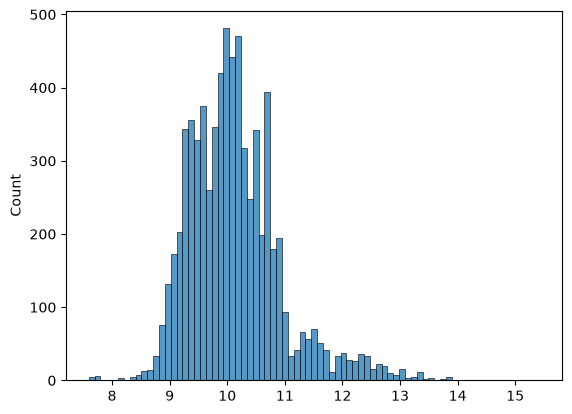

In [67]:
sns.histplot(y_pred)

<Axes: ylabel='Count'>

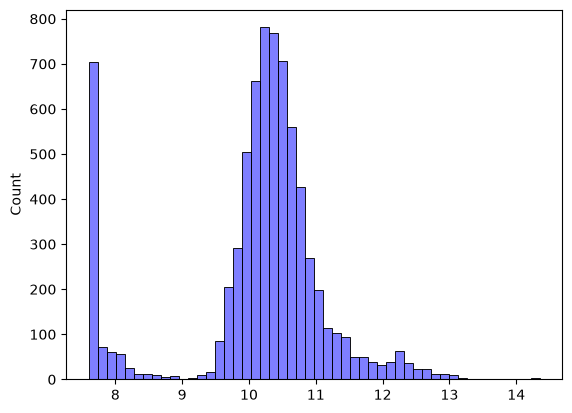

In [68]:
sns.histplot(y_train,color='blue',alpha=0.5,bins=50)

In [69]:
def rmse(y,y_pred):
    se=(y-y_pred)**2
    mse=se.mean()
    return np.sqrt(mse)

In [70]:
rmse(y_train,y_pred)

np.float64(0.7410411617289232)

In [71]:
X_train=prepare_X(df_train)
w0,w=train_linear_regression(X_train,y_train)

X_val=prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

NameError: name 'prepare_X' is not defined

In [80]:
def prepare_X(df):
    df['age']=2017-df.year
    features=base+['age']

    df_num=df[features]
    df_num=df_num.fillna(0)
    X=df_num.values
    return X

In [81]:
def prepare_X(df):
    df=df.copy()
    df['age']=2017-df.year
    features=base+['age']

    df_num=df[features]
    df_num=df_num.fillna(0)
    X=df_num.values
    return X

In [82]:
X_train=prepare_X(df_train)
w0,w=train_linear_regression(X_train,y_train)

X_val=prepare_X(df_val)
y_pred=w0+X_val.dot(w)

rmse(y_val,y_pred)

np.float64(0.5247409244255131)

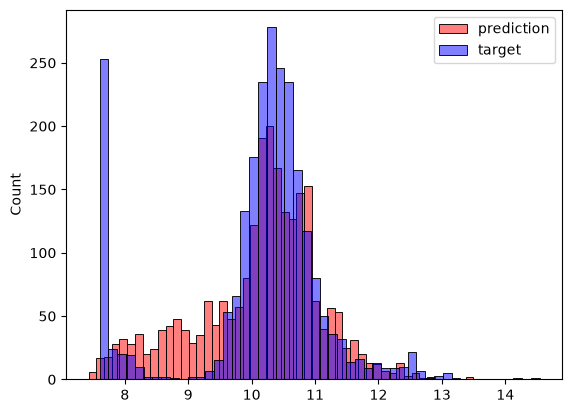

In [83]:
sns.histplot(y_pred, label='prediction', color='red', alpha=0.5, bins=50)
sns.histplot(y_val, label='target', color='blue',  alpha=0.5, bins=50)
plt.legend()

In [84]:
df_train['num_doors_4']=(df_train.number_of_doors==4).astype('int')
df_train['num_doors_3']=(df_train.number_of_doors==3).astype('int')
df_train['num_doors_2']=(df_train.number_of_doors==2).astype('int')

In [85]:
def prepare_X(df):
    df=df.copy()
    features=base.copy()

    df['age']=2017-df.year
    features.append('age')

    for v in [2,3,4]:
        df['num_doors_%s' % v]=(df.number_of_doors==v).astype('int')
        features.append('num_doors_%s' % v)

    df_num=df[features]
    df_num=df_num.fillna(0)
    X=df_num.values

    return X

In [86]:
prepare_X(df)1])

SyntaxError: unmatched ']' (12732801.py, line 1)

In [87]:
X_train =prepare_X(df_train)
w0,w=train_linear_regression(X_train,y_train)

X_val=prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

np.float64(0.5224790340046147)

In [88]:
df.make.value_counts().head()

make
chevrolet     1123
ford           881
volkswagen     809
toyota         746
dodge          626
Name: count, dtype: int64

In [89]:
makes=list(df.make.value_counts().head().index)

In [90]:
for v in makes:
   
    df['make_%s' % v]=(df.make==v).astype('int')
    features.append('make_%s' %v)

NameError: name 'features' is not defined

In [91]:
categorical_variables=[
    'make','engine_fuel_type','transmission_type','driven_wheels',
    'market_category','vehicle_size','vehicle_style']
categories={}

for c in categorical_variables:
    categories[c]=list(df_train[c].value_counts().head().index)

In [92]:
for c, values in categories.items():
  
    for v in values:
        df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
        features.append('%s_%s' % (c, v))

NameError: name 'features' is not defined

In [93]:
X_train=prepare_X(df_train)
w0,w=train_linear_regression(X_train,y_train)

X_val=prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

np.float64(0.5224790340046147)

In [94]:
X_train = prepare_X(df_train)

print("Training matrix shape:", X_train.shape)
print("Number of features:", X_train.shape[1])

Training matrix shape: (7150, 9)
Number of features: 9


In [95]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    # Create age
    df['age'] = 2017 - df.year
    features.append('age')

    # Create door-count features
    for v in [2, 3, 4]:
        col = f'num_doors_{v}'
        df[col] = (df.number_of_doors == v).astype(int)
        features.append(col)

    # Create categorical features
    for c, values in categories.items():
        for v in values:
            col = f'{c}_{v}'
            df[col] = (df[c] == v).astype(int)
            features.append(col)

    df_num = df[features]
    df_num = df_num.fillna(0)

    return df_num.to_numpy()

In [96]:
X_train=prepare_X(df_train)
w0,w=train_linear_regression(X_train,y_train)

X_val=prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

np.float64(20.08230218553892)

In [97]:
X_train = prepare_X(df_train)

print("Shape:", X_train.shape)
print("Number of features:", X_train.shape[1])

Shape: (7150, 41)
Number of features: 41


In [98]:
def train_linear_regression_reg(X,y,r=0.001):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])

    XTX=X.T.dot(X)
    XTX=XTX + r*np.eye(XTX.shape[0])

    XTX_inv=np.linalg.inv(XTX)
    w_full=XTX_inv.dot(X.T).dot(y)


    return w_full[0],w_full[1:]

In [99]:
X_train=prepare_X(df_train)
w0,w=train_linear_regression_reg(X_train,y_train,r=0.01)

X_val=prepare_X(df_val)
y_pred=w0+X_val.dot(w)
rmse(y_val,y_pred)

np.float64(0.4664260451644928)

In [100]:
for r in[0.0,0.00001,0.0001,0.001,0.1,1,10]:
    X_train=prepare_X(df_train)
    w0,w=train_linear_regression_reg(X_train,y_train,r=r)

    X_val=prepare_X(df_val)
    y_pred=w0 + X_val.dot(w)
    score=rmse(y_val,y_pred)

    print(r,w0,score)

0.0 4742977349426592.0 20.08230218553892
1e-05 11.115573429999875 0.4664501368351299
0.0001 6.847075202303205 0.4664499003947626
0.001 6.8732213469273225 0.4664476606098871
0.1 6.689554482060453 0.46627731204460837
1 5.807974896725142 0.4670908580986516
10 4.20514071265176 0.48430785735549253


In [101]:
df_full_train=pd.concat([df_train,df_val])

In [102]:
df_full_train=df_full_train.reset_index(drop=True)

In [103]:
X_full_train=prepare_X(df_full_train)

In [104]:
y_full_train=np.concatenate([y_train,y_val])

In [105]:
w0,w=train_linear_regression_reg(X_full_train,y_full_train,r=0.001)

In [107]:
X_test=prepare_X(df_test)
y_pred=w0+X_test.dot(w)
score=rmse(y_test,y_pred)

In [108]:
score

np.float64(0.5135546491151998)

In [109]:
car=df_test.iloc[20].to_dict()

In [110]:
car

{'make': 'honda',
 'model': 'civic',
 'year': 2015,
 'engine_fuel_type': 'natural_gas',
 'engine_hp': 110.0,
 'engine_cylinders': 4.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'compact',
 'vehicle_style': 'sedan',
 'highway_mpg': 38,
 'city_mpg': 27,
 'popularity': 2202}

In [111]:
df_small=pd.DataFrame([car])

In [112]:
X_small=prepare_X(df_small)

In [113]:
y_pred=w0+X_small.dot(w)
y_pred=y_pred[0]
y_pred

np.float64(10.451664973296227)

In [114]:
np.expm1(y_pred)

np.float64(34600.93807814178)